# Decision Tree Classifier From Scratch Using ID3 and Gini Impurity

**AI/ML Laboratory - Assignment A_02**

This notebook implements two categorical decision-tree classifiers from scratch:

1. **ID3:** chooses the feature with the highest Information Gain, calculated using Entropy.
2. **Gini-based tree:** chooses the feature with the largest reduction in Gini Impurity.

Both implementations use multiway categorical splits (one child for each observed value of the selected feature). No scikit-learn or other machine-learning library is used for splitting, tree construction, or prediction.

### Notebook workflow

- Inspect every CSV file available in the dataset directory and justify the selected file.
- Preserve the original categorical feature values rather than treating category codes as continuous numbers.
- Create one stratified 80/20 train-test split and reuse it for both algorithms.
- Build both trees recursively, visualize them, save the PNG files, test them, predict custom examples, and export a comparison CSV.


## 1. Dataset exploration and CSV selection

The uploaded files include the original categorical CSV, a label-encoded CSV, a one-hot-encoded CSV, and a dataset description. The original CSV is the most suitable input for this assignment because both ID3 and the Gini implementation below split **categorical attributes by their observed values**.

- The label-encoded CSV changes category names into integers. Those integer codes are identifiers, not measurements, and must not be treated as ordered numeric quantities.
- The one-hot CSV expands each original attribute into multiple binary columns. It is useful for some modelling workflows, but it changes the six original categorical attributes into a different feature representation.
- The original CSV retains the six categorical attributes directly, making multiway categorical splitting transparent and easy to interpret.

The code below scans and summarizes all CSV files it can find. In Kaggle, add the dataset to the notebook using **Add Input**. The search checks `/kaggle/input` automatically; it also checks `/mnt/data` and the notebook's current directory for local execution.


In [1]:
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Kaggle stores attached datasets under /kaggle/input.
# /mnt/data is included for the files supplied with this conversation/local run.
SEARCH_ROOTS = [Path("/kaggle/input"), Path("/mnt/data"), Path.cwd()]

csv_paths = []
seen_paths = set()
for root in SEARCH_ROOTS:
    if not root.exists():
        continue
    candidates = root.rglob("*.csv") if str(root) == "/kaggle/input" else root.glob("*.csv")
    for path in candidates:
        resolved = path.resolve()
        if resolved not in seen_paths and path.is_file():
            seen_paths.add(resolved)
            csv_paths.append(path)

if not csv_paths:
    raise FileNotFoundError(
        "No CSV files were found. In Kaggle, click Add Input and attach the Car Evaluation dataset."
    )

# Read and display a compact inventory of every discovered CSV file.
csv_inventory = []
csv_frames = {}
for path in sorted(csv_paths, key=lambda p: str(p).lower()):
    try:
        frame = pd.read_csv(path)
        csv_frames[path.resolve()] = frame
        csv_inventory.append({
            "file": path.name,
            "rows": frame.shape[0],
            "columns_count": frame.shape[1],
            "columns": ", ".join(map(str, frame.columns)),
            "missing_cells": int(frame.isna().sum().sum()),
        })
    except Exception as exc:
        csv_inventory.append({
            "file": path.name,
            "rows": "could not read",
            "columns_count": "-",
            "columns": str(exc),
            "missing_cells": "-",
        })

inventory_df = pd.DataFrame(csv_inventory)
print(f"CSV files discovered: {len(csv_inventory)}")
display(inventory_df)

FEATURES = [
    "Buying_Price",
    "Maintenance_Price",
    "No_of_Doors",
    "persons",
    "lug_boot",
    "safety",
]
TARGET = "class"
REQUIRED_COLUMNS = set(FEATURES + [TARGET])

# Prefer the explicitly named original file. If the filename differs in Kaggle,
# select a file with the six required feature columns stored as categorical/text data.
original_candidates = [
    path for path in csv_paths
    if "original" in path.stem.lower()
    and REQUIRED_COLUMNS.issubset(set(csv_frames.get(path.resolve(), pd.DataFrame()).columns))
]

if original_candidates:
    DATA_PATH = original_candidates[0]
else:
    categorical_candidates = []
    for path in csv_paths:
        frame = csv_frames.get(path.resolve())
        if frame is None or not REQUIRED_COLUMNS.issubset(set(frame.columns)):
            continue
        feature_types = [frame[col].dtype == "object" or str(frame[col].dtype).startswith("category") for col in FEATURES]
        if all(feature_types):
            categorical_candidates.append(path)
    if not categorical_candidates:
        raise FileNotFoundError(
            "Could not identify the original categorical CSV. Update DATA_PATH to the original Car Evaluation CSV."
        )
    DATA_PATH = categorical_candidates[0]

print("\nSelected file:", DATA_PATH)
data = pd.read_csv(DATA_PATH)
print("Selected dataset shape:", data.shape)
print("Columns:", list(data.columns))
print("\nFirst five rows:")
display(data.head())
print("\nData types:")
display(data.dtypes.rename("dtype").to_frame())
print("\nMissing values per column:")
display(data.isna().sum().rename("missing_values").to_frame())


CSV files discovered: 4


,file,rows,columns_count,columns,missing_cells
0,Car_Evaluation Original Dataset.csv,1728,7,"Buying_Price, Maintenance_Price, No_of_Doors, ...",0
1,Car_Evaluation_Label_encode.csv,1728,7,"Buying_Price, Maintenance_Price, No_of_Doors, ...",0
2,Car_Evaluation_OneHot_encode.csv,1728,22,"class, Buying_Price_high, Buying_Price_low, Bu...",0
3,description.csv,1,1,Description,0



Selected file: /kaggle/input/datasets/imarijit/car-evaluation/Car_Evaluation Original Dataset.csv
Selected dataset shape: (1728, 7)
Columns: ['Buying_Price', 'Maintenance_Price', 'No_of_Doors', 'persons', 'lug_boot', 'safety', 'class']

First five rows:


,Buying_Price,Maintenance_Price,No_of_Doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,0
1,vhigh,vhigh,2,2,small,med,0
2,vhigh,vhigh,2,2,small,high,0
3,vhigh,vhigh,2,2,med,low,0
4,vhigh,vhigh,2,2,med,med,0



Data types:


,dtype
Buying_Price,object
Maintenance_Price,object
No_of_Doors,object
persons,object
lug_boot,object
safety,object
class,int64



Missing values per column:


,missing_values
Buying_Price,0
Maintenance_Price,0
No_of_Doors,0
persons,0
lug_boot,0
safety,0
class,0


### Feature and target selection

The selected input features are:

| Feature | Meaning | Observed categories |
|---|---|---|
| `Buying_Price` | Buying price | `vhigh`, `high`, `med`, `low` |
| `Maintenance_Price` | Maintenance price | `vhigh`, `high`, `med`, `low` |
| `No_of_Doors` | Number of doors | `2`, `3`, `4`, `5more` |
| `persons` | Passenger capacity | `2`, `4`, `more` |
| `lug_boot` | Luggage boot size | `small`, `med`, `big` |
| `safety` | Safety level | `low`, `med`, `high` |

The target is `class`, the overall car evaluation. The supplied `description.csv` documents the numeric mapping as `0 = unacc`, `1 = acc`, `2 = good`, and `3 = vgood`. The target is converted to readable labels for reporting; the six input attributes remain categorical strings.

The original file has no missing values in the supplied copy. The target distribution is imbalanced, so the train-test split below is stratified to preserve the approximate class proportions in both sets.


In [2]:
# Convert the target codes to readable class names while preserving feature categories.
CLASS_LABEL_MAP = {
    "0": "unacc",
    "1": "acc",
    "2": "good",
    "3": "vgood",
}

missing_required = [col for col in FEATURES + [TARGET] if col not in data.columns]
if missing_required:
    raise ValueError(f"Selected CSV is missing required columns: {missing_required}")

if data[FEATURES + [TARGET]].isna().any().any():
    raise ValueError("The selected dataset contains missing values. Inspect and handle them before training.")

X = data[FEATURES].copy()
for feature in FEATURES:
    X[feature] = X[feature].astype(str).str.strip()

y_raw = data[TARGET].astype(str).str.strip()
y = y_raw.replace(CLASS_LABEL_MAP).to_numpy(dtype=str)

CLASS_ORDER = [label for label in ["unacc", "acc", "good", "vgood"] if label in set(y)]

print("Input feature names:", FEATURES)
print("Target variable:", TARGET)
print("Number of samples:", len(data))
print("\nUnique categories per input feature:")
for feature in FEATURES:
    print(f"{feature}: {sorted(X[feature].unique().tolist())}")

class_distribution = pd.Series(y, name="class_name").value_counts().reindex(CLASS_ORDER, fill_value=0)
class_distribution_df = pd.DataFrame({
    "count": class_distribution,
    "percentage": (class_distribution / len(y) * 100).round(2),
})
print("\nTarget class distribution:")
display(class_distribution_df)


Input feature names: ['Buying_Price', 'Maintenance_Price', 'No_of_Doors', 'persons', 'lug_boot', 'safety']
Target variable: class
Number of samples: 1728

Unique categories per input feature:
Buying_Price: ['high', 'low', 'med', 'vhigh']
Maintenance_Price: ['high', 'low', 'med', 'vhigh']
No_of_Doors: ['2', '3', '4', '5more']
persons: ['2', '4', 'more']
lug_boot: ['big', 'med', 'small']
safety: ['high', 'low', 'med']

Target class distribution:


,count,percentage
class_name,,
unacc,1210,70.02
acc,384,22.22
good,69,3.99
vgood,65,3.76


## 2. Train-test split (without scikit-learn)

A stratified 80/20 split is performed manually using NumPy. Each class is shuffled separately before its test records are selected. The same training and test records are then used for ID3 and Gini, which makes the accuracy comparison fair and reproducible.


In [3]:
def stratified_split_indices(labels, test_size=0.20, random_seed=42):
    """Return train and test row indices while preserving each class proportion."""
    labels = np.asarray(labels)
    rng = np.random.default_rng(random_seed)
    train_indices = []
    test_indices = []

    for class_name in sorted(np.unique(labels)):
        class_indices = np.flatnonzero(labels == class_name)
        class_indices = rng.permutation(class_indices)
        if len(class_indices) < 2:
            raise ValueError(f"Class {class_name!r} needs at least two samples for a train-test split.")
        number_test = int(round(len(class_indices) * test_size))
        number_test = max(1, min(number_test, len(class_indices) - 1))
        test_indices.extend(class_indices[:number_test])
        train_indices.extend(class_indices[number_test:])

    return rng.permutation(train_indices), rng.permutation(test_indices)


train_indices, test_indices = stratified_split_indices(y, test_size=0.20, random_seed=42)
X_train = X.iloc[train_indices].reset_index(drop=True)
X_test = X.iloc[test_indices].reset_index(drop=True)
y_train = y[train_indices]
y_test = y[test_indices]

print(f"Training records: {len(X_train)} ({len(X_train) / len(X):.1%})")
print(f"Testing records : {len(X_test)} ({len(X_test) / len(X):.1%})")

split_summary = pd.DataFrame({
    "all_data": pd.Series(y).value_counts().reindex(CLASS_ORDER, fill_value=0),
    "training": pd.Series(y_train).value_counts().reindex(CLASS_ORDER, fill_value=0),
    "testing": pd.Series(y_test).value_counts().reindex(CLASS_ORDER, fill_value=0),
})
print("\nClass counts in each split:")
display(split_summary)


Training records: 1382 (80.0%)
Testing records : 346 (20.0%)

Class counts in each split:


,all_data,training,testing
unacc,1210,968,242
acc,384,307,77
good,69,55,14
vgood,65,52,13


## 3. ID3 and Gini decision-tree implementations

### Splitting criteria

**Entropy** measures class uncertainty:

\[
H(S) = -\sum_{i=1}^{k} p_i \log_2(p_i)
\]

**Information Gain** is the reduction in entropy after splitting on an attribute:

\[
IG(S,A) = H(S) - \sum_{v \in Values(A)} \frac{|S_v|}{|S|} H(S_v)
\]

**Gini Impurity** measures class mixing:

\[
Gini(S) = 1 - \sum_{i=1}^{k} p_i^2
\]

For the Gini tree, the chosen attribute is the one with the largest reduction in weighted Gini impurity:

\[
\Delta Gini(S,A) = Gini(S) - \sum_{v \in Values(A)} \frac{|S_v|}{|S|} Gini(S_v)
\]

At each node, both algorithms evaluate every remaining feature. They create one branch for each category observed for the selected feature. A branch is a leaf when its records belong to one class, when no features remain, or when no positive impurity reduction is available. Each node stores its majority class so an unseen category at prediction time can safely fall back to that node's majority class.


In [4]:
def entropy(labels):
    """Calculate Shannon entropy for a one-dimensional collection of class labels."""
    labels = np.asarray(labels)
    if len(labels) == 0:
        return 0.0
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()
    return float(-np.sum(probabilities * np.log2(probabilities)))


def gini_impurity(labels):
    """Calculate Gini impurity for a one-dimensional collection of class labels."""
    labels = np.asarray(labels)
    if len(labels) == 0:
        return 0.0
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()
    return float(1.0 - np.sum(probabilities ** 2))


def weighted_child_impurity(X_part, y_part, attribute, impurity_function):
    """Calculate the weighted impurity of all category branches for one attribute."""
    values = sorted(X_part[attribute].astype(str).unique().tolist())
    weighted = 0.0
    for value in values:
        mask = X_part[attribute].astype(str).to_numpy() == value
        branch_labels = y_part[mask]
        weighted += (len(branch_labels) / len(y_part)) * impurity_function(branch_labels)
    return float(weighted)


def information_gain(X_part, y_part, attribute):
    """Entropy reduction obtained by splitting on the given categorical attribute."""
    return entropy(y_part) - weighted_child_impurity(X_part, y_part, attribute, entropy)


def gini_gain(X_part, y_part, attribute):
    """Gini impurity reduction obtained by splitting on the given categorical attribute."""
    return gini_impurity(y_part) - weighted_child_impurity(X_part, y_part, attribute, gini_impurity)


def majority_class(labels):
    """Return the most frequent label; alphabetical order breaks ties reproducibly."""
    counts = Counter(np.asarray(labels).tolist())
    return min(counts.items(), key=lambda item: (-item[1], item[0]))[0]


class TreeNode:
    """A node in a categorical decision tree."""
    def __init__(self, prediction, class_counts, impurity, sample_count):
        self.prediction = prediction
        self.class_counts = class_counts
        self.impurity = float(impurity)
        self.sample_count = int(sample_count)
        self.attribute = None       # None means this node is a leaf.
        self.branches = {}          # category value -> child TreeNode
        self.split_gain = 0.0


def build_decision_tree(X_train, y_train, criterion="entropy", min_gain=1e-12):
    """Build an ID3 (entropy) or Gini tree recursively, without ML libraries."""
    if criterion not in {"entropy", "gini"}:
        raise ValueError("criterion must be either 'entropy' or 'gini'")

    X_local = X_train.reset_index(drop=True).copy()
    y_local = np.asarray(y_train, dtype=str)
    impurity_function = entropy if criterion == "entropy" else gini_impurity
    gain_function = information_gain if criterion == "entropy" else gini_gain

    def grow(X_part, y_part, available_features):
        counts = Counter(y_part.tolist())
        prediction = majority_class(y_part)
        current_impurity = impurity_function(y_part)
        node = TreeNode(
            prediction=prediction,
            class_counts=dict(counts),
            impurity=current_impurity,
            sample_count=len(y_part),
        )

        # Stopping condition 1: all examples at this node have the same class.
        if len(counts) == 1:
            return node

        # Stopping condition 2: no remaining input attributes are available.
        if not available_features:
            return node

        # Choose the attribute with the largest impurity reduction.
        best_attribute = None
        best_gain = -float("inf")
        for attribute in available_features:
            gain = gain_function(X_part, y_part, attribute)
            if gain > best_gain + 1e-12:
                best_gain = gain
                best_attribute = attribute

        # Stopping condition 3: no meaningful positive impurity reduction exists.
        if best_attribute is None or best_gain <= min_gain:
            return node

        node.attribute = best_attribute
        node.split_gain = float(best_gain)
        remaining_features = [f for f in available_features if f != best_attribute]

        # Multiway split: one child for every category observed at this node.
        for value in sorted(X_part[best_attribute].astype(str).unique().tolist()):
            mask = X_part[best_attribute].astype(str).to_numpy() == value
            child_X = X_part.loc[mask, remaining_features].reset_index(drop=True)
            child_y = y_part[mask]
            node.branches[value] = grow(child_X, child_y, remaining_features)

        return node

    return grow(X_local, y_local, list(X_local.columns))


def predict_one(tree, row):
    """Predict one record. Unknown category values use the current node's majority class."""
    node = tree
    while node.attribute is not None:
        value = str(row[node.attribute]).strip()
        if value not in node.branches:
            return node.prediction
        node = node.branches[value]
    return node.prediction


def predict_many(tree, X_records):
    """Predict labels for a DataFrame of records."""
    return np.asarray([predict_one(tree, row) for _, row in X_records.iterrows()], dtype=str)


def tree_statistics(tree):
    """Return maximum root-to-leaf depth, total nodes, and leaf count."""
    def visit(node, depth):
        if node.attribute is None:
            return depth, 1, 1
        child_results = [visit(child, depth + 1) for child in node.branches.values()]
        maximum_depth = max(result[0] for result in child_results)
        total_nodes = 1 + sum(result[1] for result in child_results)
        total_leaves = sum(result[2] for result in child_results)
        return maximum_depth, total_nodes, total_leaves

    depth, nodes, leaves = visit(tree, 0)
    return {"depth": depth, "nodes": nodes, "leaves": leaves}


def trees_have_same_structure(tree_a, tree_b):
    """Compare split attributes, branch values, and leaf predictions recursively."""
    if tree_a.attribute != tree_b.attribute or tree_a.prediction != tree_b.prediction:
        return False
    if set(tree_a.branches) != set(tree_b.branches):
        return False
    return all(
        trees_have_same_structure(tree_a.branches[value], tree_b.branches[value])
        for value in tree_a.branches
    )

print("Entropy of all training labels:", round(entropy(y_train), 6))
print("Gini impurity of all training labels:", round(gini_impurity(y_train), 6))
print("\nRoot-level split scores by feature:")
root_scores = pd.DataFrame({
    "feature": FEATURES,
    "information_gain": [information_gain(X_train, y_train, f) for f in FEATURES],
    "gini_reduction": [gini_gain(X_train, y_train, f) for f in FEATURES],
}).sort_values("information_gain", ascending=False).reset_index(drop=True)
display(root_scores)


Entropy of all training labels: 1.205103
Gini impurity of all training labels: 0.457045

Root-level split scores by feature:


,feature,information_gain,gini_reduction
0,safety,0.268550,0.079280
1,persons,0.221993,0.072074
2,Buying_Price,0.099495,0.015221
3,Maintenance_Price,0.075952,0.012094
4,lug_boot,0.027998,0.004179
5,No_of_Doors,0.004194,0.001459


## 4. Train the two decision trees

The following cell builds the trees independently from the same training subset. The code uses only the custom functions above for attribute selection, recursion, and prediction.


In [5]:
id3_tree = build_decision_tree(X_train, y_train, criterion="entropy")
gini_tree = build_decision_tree(X_train, y_train, criterion="gini")

id3_stats = tree_statistics(id3_tree)
gini_stats = tree_statistics(gini_tree)

print("ID3 tree")
print("  Root attribute:", id3_tree.attribute)
print("  Root entropy:", round(id3_tree.impurity, 6))
print("  Root information gain:", round(id3_tree.split_gain, 6))
print("  Depth / nodes / leaves:", id3_stats["depth"], "/", id3_stats["nodes"], "/", id3_stats["leaves"])

print("\nGini-based tree")
print("  Root attribute:", gini_tree.attribute)
print("  Root Gini impurity:", round(gini_tree.impurity, 6))
print("  Root Gini reduction:", round(gini_tree.split_gain, 6))
print("  Depth / nodes / leaves:", gini_stats["depth"], "/", gini_stats["nodes"], "/", gini_stats["leaves"])

same_structure = trees_have_same_structure(id3_tree, gini_tree)
print("\nDo the trees have identical split structure and leaf predictions?", same_structure)


ID3 tree
  Root attribute: safety
  Root entropy: 1.205103
  Root information gain: 0.26855
  Depth / nodes / leaves: 6 / 323 / 229

Gini-based tree
  Root attribute: safety
  Root Gini impurity: 0.457045
  Root Gini reduction: 0.07928
  Depth / nodes / leaves: 6 / 323 / 229

Do the trees have identical split structure and leaf predictions? True


## 5. Tree visualization and PNG export

The visualizations show each internal decision attribute, the impurity at that node, the impurity reduction used to select its split, the category on each branch, and the predicted class at each leaf. Graphviz is used only for drawing the trees, as permitted in the assignment. A Matplotlib fallback is included for environments without Graphviz.


Saved Graphviz tree: /kaggle/working/ID3_Entropy_Decision_Tree.png
Saved Graphviz tree: /kaggle/working/Gini_Impurity_Decision_Tree.png

Visualization files:
ID3_Entropy_Decision_Tree.png: 3,181,744 bytes
Gini_Impurity_Decision_Tree.png: 3,107,536 bytes
ID3 tree preview:


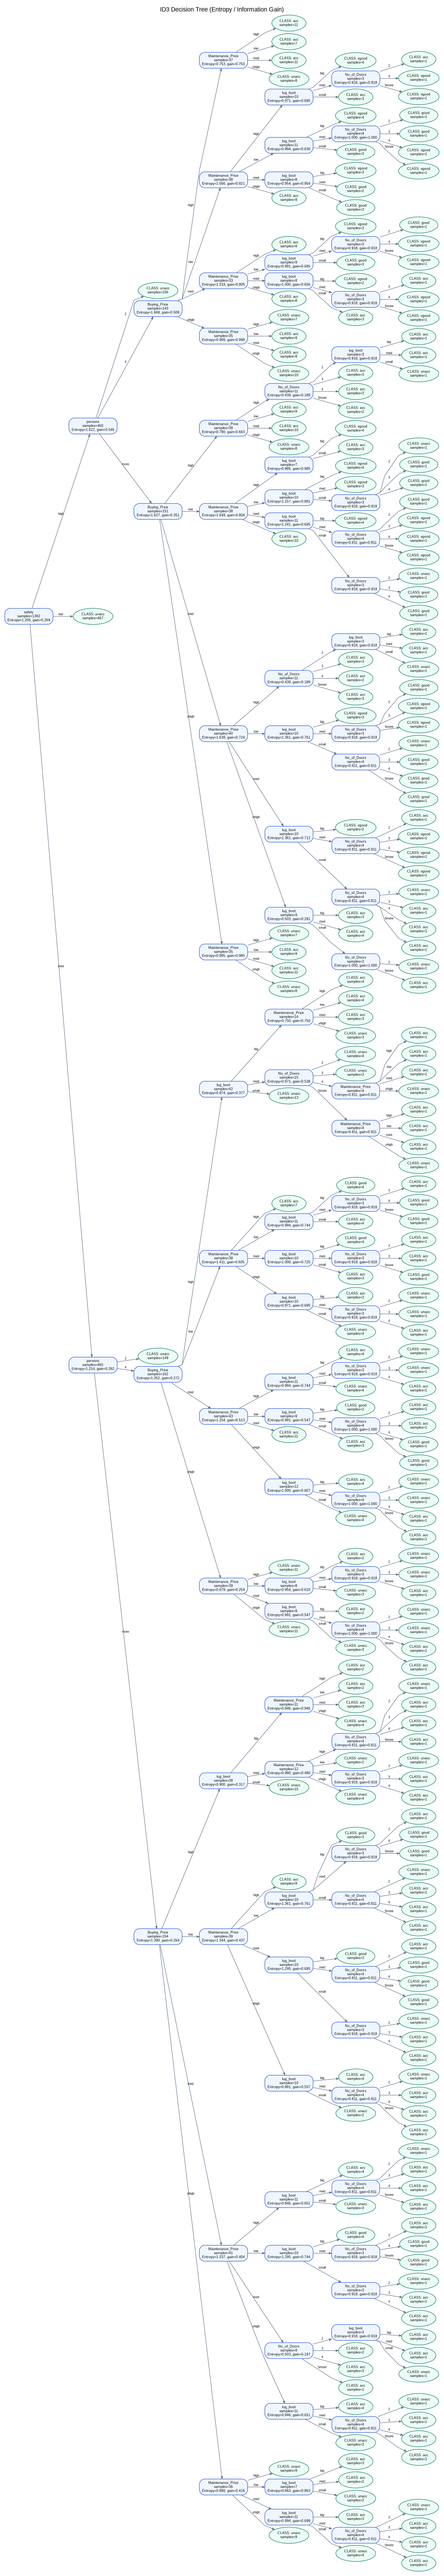

Gini tree preview:


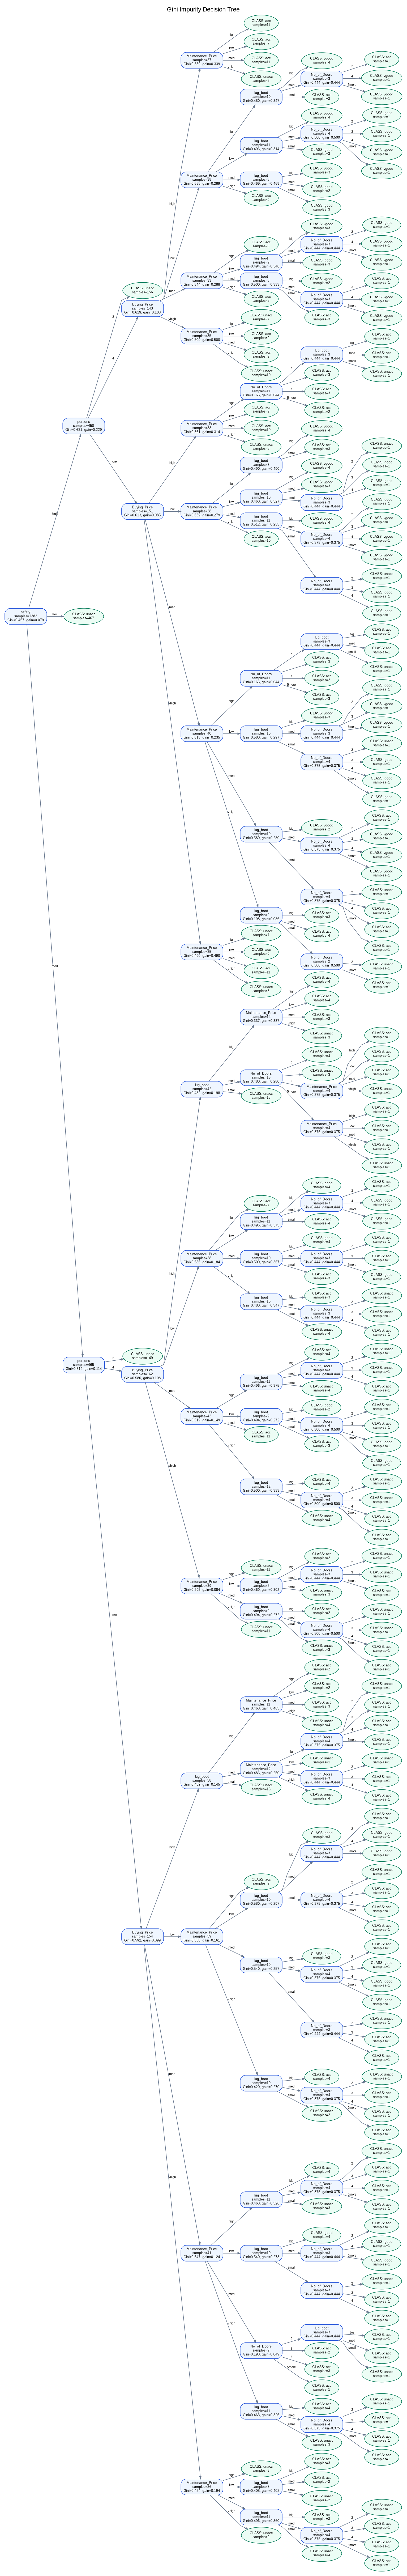

In [6]:
from pathlib import Path
from IPython.display import display, Image

OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def save_tree_graphviz(tree, criterion, output_path):
    """Render a complete tree with Graphviz. This function is used only for visualization."""
    from graphviz import Digraph

    dot = Digraph(name=f"{criterion}_decision_tree", format="png")
    # A left-to-right layout keeps the complete tree in a portrait-oriented PNG.
    title = "ID3 Decision Tree (Entropy / Information Gain)" if criterion == "entropy" else "Gini Impurity Decision Tree"
    dot.attr(
        "graph", rankdir="LR", bgcolor="white", nodesep="0.07", ranksep="0.30",
        splines="polyline", pad="0.15", concentrate="true", dpi="120",
        labelloc="t", label=title, fontsize="14", fontname="Helvetica"
    )
    dot.attr(
        "node", shape="box", style="rounded,filled", fontname="Helvetica",
        fontsize="8", margin="0.09,0.05", color="#334155", fillcolor="#eff6ff"
    )
    dot.attr("edge", fontname="Helvetica", fontsize="7", color="#64748b", arrowsize="0.55")

    counter = {"value": 0}

    def add_node(node, parent_id=None, edge_label=None):
        node_id = f"node_{counter['value']}"
        counter["value"] += 1

        if node.attribute is None:
            label = (
                f"CLASS: {node.prediction}\\n"
                f"samples={node.sample_count}"
            )
            dot.node(node_id, label=label, shape="ellipse", fillcolor="#ecfdf5", color="#047857")
        else:
            impurity_name = "Entropy" if criterion == "entropy" else "Gini"
            label = (
                f"{node.attribute}\\n"
                f"samples={node.sample_count}\\n"
                f"{impurity_name}={node.impurity:.3f}, gain={node.split_gain:.3f}"
            )
            dot.node(node_id, label=label, fillcolor="#eff6ff", color="#1d4ed8")

        if parent_id is not None:
            dot.edge(parent_id, node_id, label=str(edge_label))

        for value, child in node.branches.items():
            add_node(child, node_id, value)

    add_node(tree)
    rendered_path = dot.render(filename=str(output_path.with_suffix("")), cleanup=True)
    return Path(rendered_path)


def save_tree_matplotlib(tree, criterion, output_path):
    """Fallback renderer that lays out every node using Matplotlib."""
    positions = {}
    edges = []
    leaf_counter = {"x": 0}

    def assign_positions(node, depth=0):
        if node.attribute is None:
            x = leaf_counter["x"]
            leaf_counter["x"] += 1
        else:
            child_x = []
            for value, child in node.branches.items():
                child_x.append(assign_positions(child, depth + 1))
                edges.append((node, child, value))
            x = float(np.mean(child_x)) if child_x else leaf_counter["x"]
        positions[id(node)] = (x, -depth)
        return x

    assign_positions(tree)
    total_leaves = max(leaf_counter["x"], 1)
    max_depth = tree_statistics(tree)["depth"]
    width = max(18, min(70, total_leaves * 0.55))
    height = max(8, max_depth * 2.0 + 3)
    fig, ax = plt.subplots(figsize=(width, height))

    for parent, child, value in edges:
        x1, y1 = positions[id(parent)]
        x2, y2 = positions[id(child)]
        ax.plot([x1, x2], [y1, y2], color="#64748b", linewidth=0.7, zorder=1)
        ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(value), fontsize=5,
                ha="center", va="center", bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8}, zorder=3)

    stack = [tree]
    while stack:
        node = stack.pop()
        x_pos, y_pos = positions[id(node)]
        if node.attribute is None:
            label = f"{node.prediction}\\nn={node.sample_count}"
            box = {"boxstyle": "round,pad=0.3", "facecolor": "#ecfdf5", "edgecolor": "#047857"}
        else:
            metric = "H" if criterion == "entropy" else "Gini"
            label = f"{node.attribute}\\nn={node.sample_count}, {metric}={node.impurity:.2f}"
            box = {"boxstyle": "round,pad=0.3", "facecolor": "#eff6ff", "edgecolor": "#1d4ed8"}
        ax.text(x_pos, y_pos, label, ha="center", va="center", fontsize=5, bbox=box, zorder=2)
        stack.extend(node.branches.values())

    ax.set_title(f"{criterion.upper()} decision tree", fontsize=12)
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.close(fig)
    return output_path


def export_tree(tree, criterion, filename):
    output_path = OUTPUT_DIR / filename
    try:
        rendered = save_tree_graphviz(tree, criterion, output_path)
        print(f"Saved Graphviz tree: {rendered}")
        return rendered
    except Exception as exc:
        print(f"Graphviz rendering unavailable ({exc}). Using Matplotlib fallback.")
        rendered = save_tree_matplotlib(tree, criterion, output_path)
        print(f"Saved Matplotlib tree: {rendered}")
        return Path(rendered)


id3_png = export_tree(id3_tree, "entropy", "ID3_Entropy_Decision_Tree.png")
gini_png = export_tree(gini_tree, "gini", "Gini_Impurity_Decision_Tree.png")

print("\nVisualization files:")
for path in [id3_png, gini_png]:
    print(f"{path.name}: {path.stat().st_size:,} bytes")

# Inline previews make the generated visualizations visible in the notebook output.
print("ID3 tree preview:")
display(Image(filename=str(id3_png), width=850))
print("Gini tree preview:")
display(Image(filename=str(gini_png), width=850))


## 6. Testing and accuracy evaluation

Accuracy is calculated manually as the number of correct test predictions divided by the number of test records. Confusion matrices and per-class precision/recall are also calculated using pandas and NumPy only; no scikit-learn metric functions are used.


In [7]:
def accuracy_score_manual(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    if len(actual) == 0:
        return 0.0
    return float(np.mean(actual == predicted))


def confusion_matrix_manual(actual, predicted, labels):
    matrix = pd.DataFrame(0, index=labels, columns=labels, dtype=int)
    for true_label, predicted_label in zip(actual, predicted):
        matrix.loc[true_label, predicted_label] += 1
    matrix.index.name = "actual"
    matrix.columns.name = "predicted"
    return matrix


def per_class_metrics(confusion):
    rows = []
    for label in confusion.index:
        true_positive = int(confusion.loc[label, label])
        false_positive = int(confusion[label].sum() - true_positive)
        false_negative = int(confusion.loc[label].sum() - true_positive)
        precision = true_positive / (true_positive + false_positive) if true_positive + false_positive else 0.0
        recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if precision + recall else 0.0
        rows.append({"class": label, "precision": precision, "recall": recall, "f1_score": f1})
    return pd.DataFrame(rows).set_index("class")


id3_train_predictions = predict_many(id3_tree, X_train)
id3_test_predictions = predict_many(id3_tree, X_test)
gini_train_predictions = predict_many(gini_tree, X_train)
gini_test_predictions = predict_many(gini_tree, X_test)

id3_train_accuracy = accuracy_score_manual(y_train, id3_train_predictions)
id3_test_accuracy = accuracy_score_manual(y_test, id3_test_predictions)
gini_train_accuracy = accuracy_score_manual(y_train, gini_train_predictions)
gini_test_accuracy = accuracy_score_manual(y_test, gini_test_predictions)

id3_confusion = confusion_matrix_manual(y_test, id3_test_predictions, CLASS_ORDER)
gini_confusion = confusion_matrix_manual(y_test, gini_test_predictions, CLASS_ORDER)

accuracy_table = pd.DataFrame({
    "Training accuracy": [id3_train_accuracy, gini_train_accuracy],
    "Testing accuracy": [id3_test_accuracy, gini_test_accuracy],
}, index=["ID3 (Entropy)", "Gini Impurity"])
print("Accuracy:")
display((accuracy_table * 100).round(2).rename(columns={
    "Training accuracy": "Training accuracy (%)",
    "Testing accuracy": "Testing accuracy (%)",
}))

print("ID3 test confusion matrix:")
display(id3_confusion)
print("Gini test confusion matrix:")
display(gini_confusion)

print("ID3 per-class metrics:")
display(per_class_metrics(id3_confusion).round(3))
print("Gini per-class metrics:")
display(per_class_metrics(gini_confusion).round(3))


Accuracy:


,Training accuracy (%),Testing accuracy (%)
ID3 (Entropy),100.0,93.35
Gini Impurity,100.0,93.35


ID3 test confusion matrix:


predicted,unacc,acc,good,vgood
actual,,,,
unacc,234,8,0,0
acc,6,67,1,3
good,0,1,11,2
vgood,0,0,2,11


Gini test confusion matrix:


predicted,unacc,acc,good,vgood
actual,,,,
unacc,234,8,0,0
acc,6,67,1,3
good,0,1,11,2
vgood,0,0,2,11


ID3 per-class metrics:


,precision,recall,f1_score
class,,,
unacc,0.975,0.967,0.971
acc,0.882,0.870,0.876
good,0.786,0.786,0.786
vgood,0.688,0.846,0.759


Gini per-class metrics:


,precision,recall,f1_score
class,,,
unacc,0.975,0.967,0.971
acc,0.882,0.870,0.876
good,0.786,0.786,0.786
vgood,0.688,0.846,0.759


## 7. Custom car configurations

The dictionaries below are editable examples of user-supplied car configurations. Change any values to categories listed in the dataset exploration section, then rerun this cell. Both trained trees predict the evaluation category for every configuration.


In [8]:
custom_cars = pd.DataFrame([
    {
        "Buying_Price": "low",
        "Maintenance_Price": "low",
        "No_of_Doors": "4",
        "persons": "4",
        "lug_boot": "big",
        "safety": "high",
    },
    {
        "Buying_Price": "vhigh",
        "Maintenance_Price": "vhigh",
        "No_of_Doors": "2",
        "persons": "2",
        "lug_boot": "small",
        "safety": "low",
    },
    {
        "Buying_Price": "med",
        "Maintenance_Price": "high",
        "No_of_Doors": "4",
        "persons": "4",
        "lug_boot": "med",
        "safety": "high",
    },
    {
        "Buying_Price": "high",
        "Maintenance_Price": "med",
        "No_of_Doors": "3",
        "persons": "more",
        "lug_boot": "big",
        "safety": "med",
    },
], columns=FEATURES)

# Validate user entries to catch misspelled or unsupported categories.
for feature in FEATURES:
    allowed_values = set(X[feature].unique())
    supplied_values = set(custom_cars[feature].astype(str))
    invalid_values = supplied_values - allowed_values
    if invalid_values:
        raise ValueError(f"Invalid value(s) for {feature}: {sorted(invalid_values)}. Allowed: {sorted(allowed_values)}")

custom_output = custom_cars.copy()
custom_output["ID3_prediction"] = predict_many(id3_tree, custom_cars)
custom_output["Gini_prediction"] = predict_many(gini_tree, custom_cars)
print("Predictions for custom car configurations:")
display(custom_output)


Predictions for custom car configurations:


,Buying_Price,Maintenance_Price,No_of_Doors,persons,lug_boot,safety,ID3_prediction,Gini_prediction
0,low,low,4,4,big,high,vgood,vgood
1,vhigh,vhigh,2,2,small,low,unacc,unacc
2,med,high,4,4,med,high,acc,acc
3,high,med,3,more,big,med,acc,acc


## 8. Comparison of ID3 and Gini-based trees

The comparison includes each tree's root attribute, maximum depth, total nodes, leaf nodes, and test accuracy. The structure check also determines whether both algorithms selected the same feature at every node and produced the same leaf predictions for this particular training split.


In [9]:
comparison_rows = [
    {
        "Algorithm": "ID3 (Entropy / Information Gain)",
        "Root attribute": id3_tree.attribute,
        "Tree depth": id3_stats["depth"],
        "Total nodes": id3_stats["nodes"],
        "Leaf nodes": id3_stats["leaves"],
        "Training accuracy": id3_train_accuracy,
        "Testing accuracy": id3_test_accuracy,
        "Root split score": id3_tree.split_gain,
    },
    {
        "Algorithm": "Gini Impurity",
        "Root attribute": gini_tree.attribute,
        "Tree depth": gini_stats["depth"],
        "Total nodes": gini_stats["nodes"],
        "Leaf nodes": gini_stats["leaves"],
        "Training accuracy": gini_train_accuracy,
        "Testing accuracy": gini_test_accuracy,
        "Root split score": gini_tree.split_gain,
    },
]
comparison_df = pd.DataFrame(comparison_rows)
comparison_csv = OUTPUT_DIR / "Decision_Tree_ID3_Gini_Comparison.csv"
comparison_df.to_csv(comparison_csv, index=False)

print("ID3 vs Gini comparison:")
comparison_display = comparison_df.copy()
comparison_display["Training accuracy (%)"] = (comparison_display.pop("Training accuracy") * 100).round(2)
comparison_display["Testing accuracy (%)"] = (comparison_display.pop("Testing accuracy") * 100).round(2)
comparison_display["Root split score"] = comparison_display["Root split score"].round(6)
display(comparison_display)
print("\nIdentical tree structure:", same_structure)
print("Comparison CSV saved to:", comparison_csv)


ID3 vs Gini comparison:


,Algorithm,Root attribute,Tree depth,Total nodes,Leaf nodes,Root split score,Training accuracy (%),Testing accuracy (%)
0,ID3 (Entropy / Information Gain),safety,6,323,229,0.26855,100.0,93.35
1,Gini Impurity,safety,6,323,229,0.07928,100.0,93.35



Identical tree structure: True
Comparison CSV saved to: /kaggle/working/Decision_Tree_ID3_Gini_Comparison.csv


## 9. Analysis and observations

### How the splitting criteria work

- **Entropy** is a measure of class uncertainty. It is zero when all records at a node belong to one class and is larger when the classes are more mixed.
- **Information Gain** measures how much a candidate attribute reduces entropy. ID3 selects the attribute with the highest Information Gain at each node.
- **Gini Impurity** also measures class mixing. A value of zero indicates a pure node. The Gini tree selects the attribute that gives the greatest reduction in weighted Gini impurity.

Both criteria prefer splits that create purer child nodes. Their formulas are different, so they can select different attributes or produce different trees on some datasets. Here, both use the same categorical, multiway split convention so the comparison isolates the impurity criterion rather than changing the representation or split type.

### Dataset-specific observations

Use the printed comparison table and model outputs above as the final numeric results for this run. The root attributes and tree structures are determined from the supplied CSV, the fixed random seed, and the stated multiway-split implementation. If the structure check is `True`, the two criteria produced the same split structure and leaf predictions on this train split, even though the numerical entropy and Gini reduction values are different. This is a dataset-specific result, not a rule that ID3 and Gini always build identical trees.

The train and test accuracy should be read together. A fully grown tree can fit training examples very closely, while its test accuracy measures how well it generalizes to unseen records. Also note that the target classes are imbalanced: the `unacc` class is much more frequent than `good` and `vgood`. Therefore, the per-class precision/recall table and confusion matrices are useful alongside overall accuracy.


In [10]:
# Print a concise, result-specific conclusion based on the values computed above.
print("RESULT SUMMARY")
print(f"ID3: root={id3_tree.attribute}, depth={id3_stats['depth']}, nodes={id3_stats['nodes']}, leaves={id3_stats['leaves']}, test_accuracy={id3_test_accuracy:.2%}")
print(f"Gini: root={gini_tree.attribute}, depth={gini_stats['depth']}, nodes={gini_stats['nodes']}, leaves={gini_stats['leaves']}, test_accuracy={gini_test_accuracy:.2%}")
if same_structure:
    print("Observation: both criteria selected the same split structure and leaf predictions on this split.")
else:
    print("Observation: the criteria produced different tree structures on this split.")

print("\nSaved deliverables:")
for path in [id3_png, gini_png, comparison_csv]:
    print(f"- {path.name} ({path.stat().st_size:,} bytes)")


RESULT SUMMARY
ID3: root=safety, depth=6, nodes=323, leaves=229, test_accuracy=93.35%
Gini: root=safety, depth=6, nodes=323, leaves=229, test_accuracy=93.35%
Observation: both criteria selected the same split structure and leaf predictions on this split.

Saved deliverables:
- ID3_Entropy_Decision_Tree.png (3,181,744 bytes)
- Gini_Impurity_Decision_Tree.png (3,107,536 bytes)
- Decision_Tree_ID3_Gini_Comparison.csv (277 bytes)
